In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv("social_media_engagement_5000.csv")

df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [6]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

In [7]:
df.shape

(5000, 19)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


In [9]:
df.isnull().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


In [12]:
numeric_columns = [
    'age',
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'impression_count',
    'follower_count',
    'engagement_rate'
]

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

In [13]:
categorical_columns = [
    'gender',
    'sentiment'
]

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [14]:
df.isnull().sum()

,0
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


In [15]:
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    dayfirst=True
)
df['posted_at'].head()

,posted_at
0,2022-12-17
1,2023-06-02
2,2023-05-07
3,2023-02-12
4,2023-05-23


In [17]:
df = df.sort_values('posted_at')

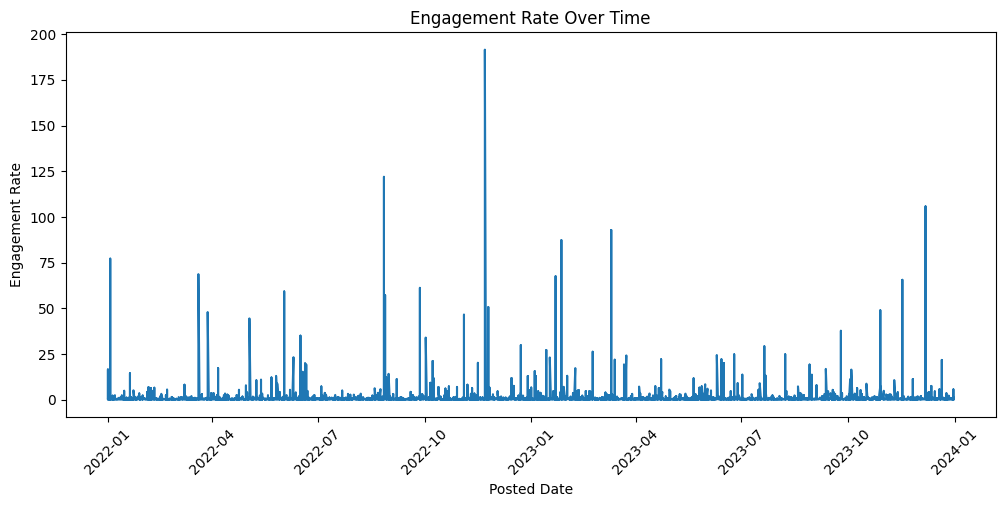

In [18]:
plt.figure(figsize=(12, 5))

plt.plot(
    df['posted_at'],
    df['engagement_rate']
)

plt.xlabel('Posted Date')
plt.ylabel('Engagement Rate')
plt.title('Engagement Rate Over Time')

plt.xticks(rotation=45)

plt.show()

In [19]:
post_type_engagement = df.groupby(
    'post_type'
)['engagement_rate'].mean()

post_type_engagement

,engagement_rate
post_type,
image,0.895646
reel,0.783047
text,1.064549
video,1.122365


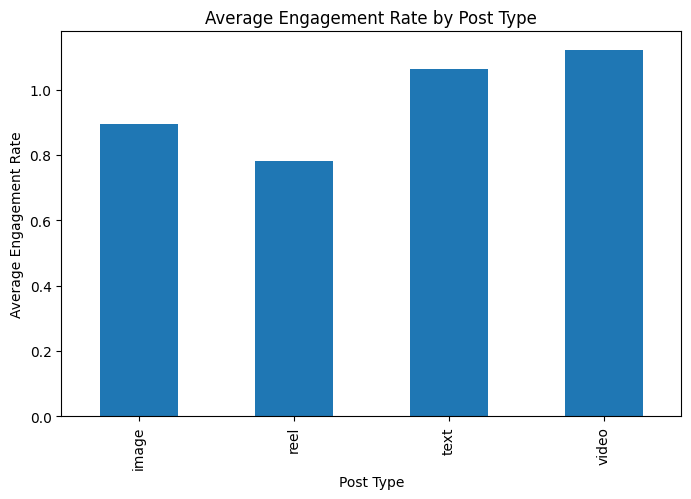

In [20]:
post_type_engagement.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Post Type')
plt.ylabel('Average Engagement Rate')
plt.title('Average Engagement Rate by Post Type')

plt.show()

In [21]:
category_engagement = df.groupby(
    'post_category'
)['engagement_rate'].mean()

category_engagement

,engagement_rate
post_category,
education,0.844222
fashion,0.807109
fitness,0.865628
food,1.358628
lifestyle,1.091019
music,0.888803
tech,1.160475
travel,0.702223


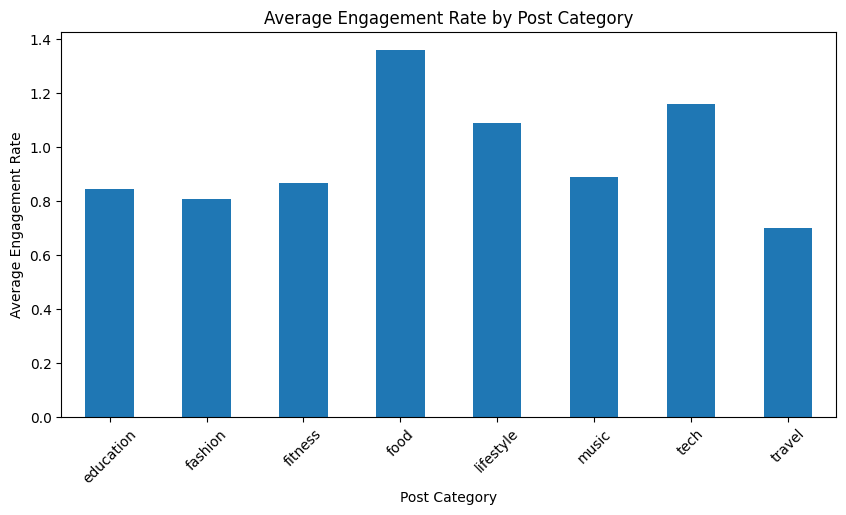

In [22]:
category_engagement.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.xlabel('Post Category')
plt.ylabel('Average Engagement Rate')
plt.title('Average Engagement Rate by Post Category')

plt.xticks(rotation=45)

plt.show()

In [23]:
sentiment_counts = df['sentiment'].value_counts()

sentiment_counts

,count
sentiment,
positive,2513
neutral,1527
negative,960


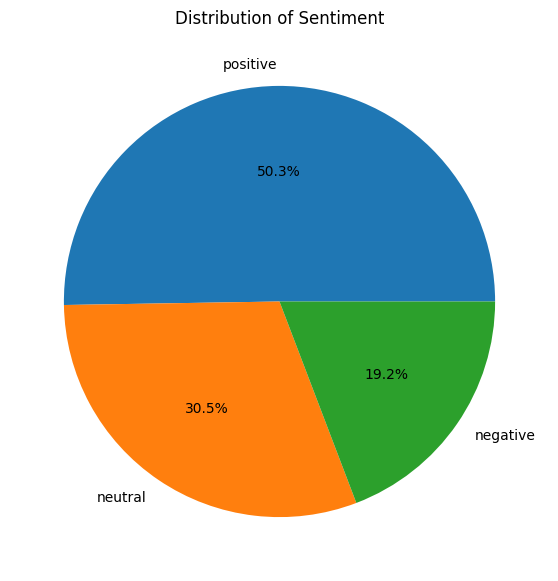

In [24]:
sentiment_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7, 7)
)

plt.title('Distribution of Sentiment')
plt.ylabel('')

plt.show()

In [25]:
sentiment_engagement = df.groupby(
    'sentiment'
)['engagement_rate'].mean()

sentiment_engagement

,engagement_rate
sentiment,
negative,1.038486
neutral,0.991170
positive,0.919744


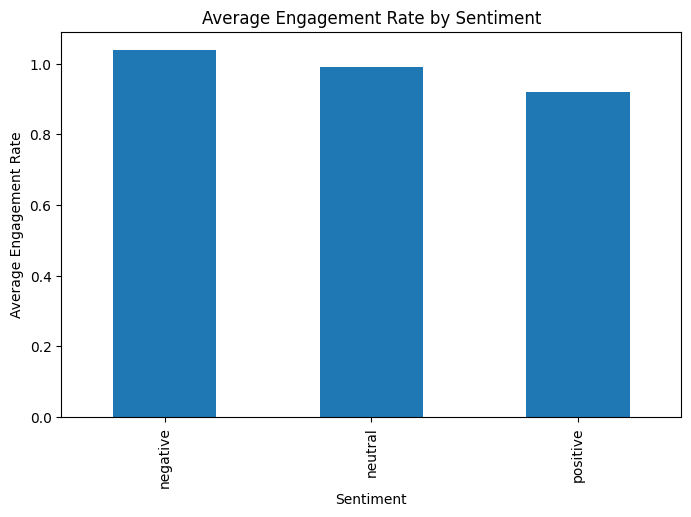

In [26]:
sentiment_engagement.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Sentiment')
plt.ylabel('Average Engagement Rate')
plt.title('Average Engagement Rate by Sentiment')

plt.show()

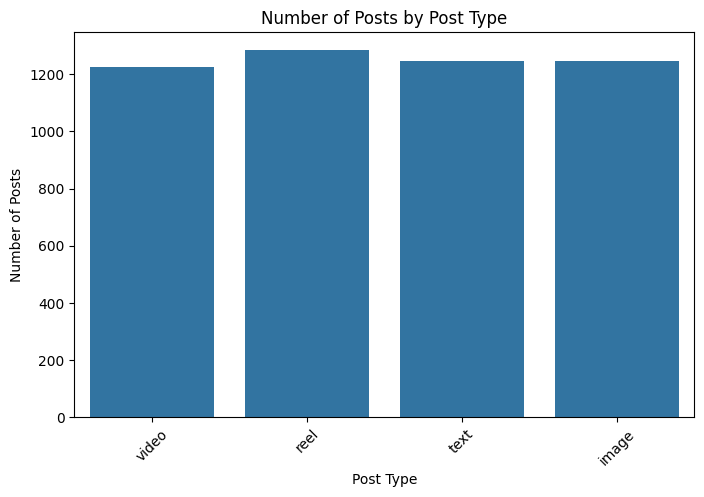

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='post_type'
)

plt.xlabel('Post Type')
plt.ylabel('Number of Posts')
plt.title('Number of Posts by Post Type')

plt.xticks(rotation=45)

plt.show()

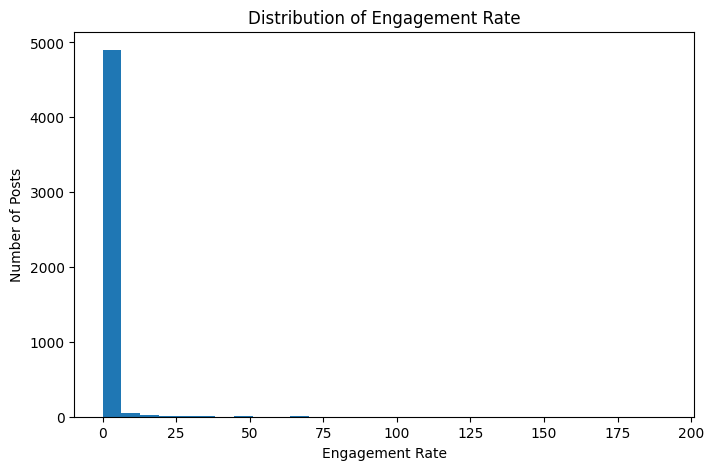

In [28]:
plt.figure(figsize=(8, 5))

plt.hist(
    df['engagement_rate'],
    bins=30
)

plt.xlabel('Engagement Rate')
plt.ylabel('Number of Posts')
plt.title('Distribution of Engagement Rate')

plt.show()

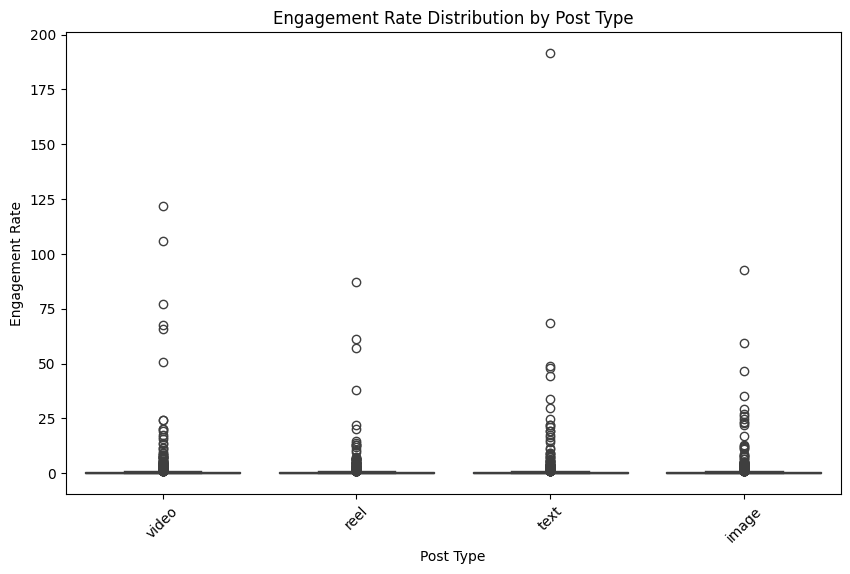

In [29]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='post_type',
    y='engagement_rate'
)

plt.xlabel('Post Type')
plt.ylabel('Engagement Rate')
plt.title('Engagement Rate Distribution by Post Type')

plt.xticks(rotation=45)

plt.show()

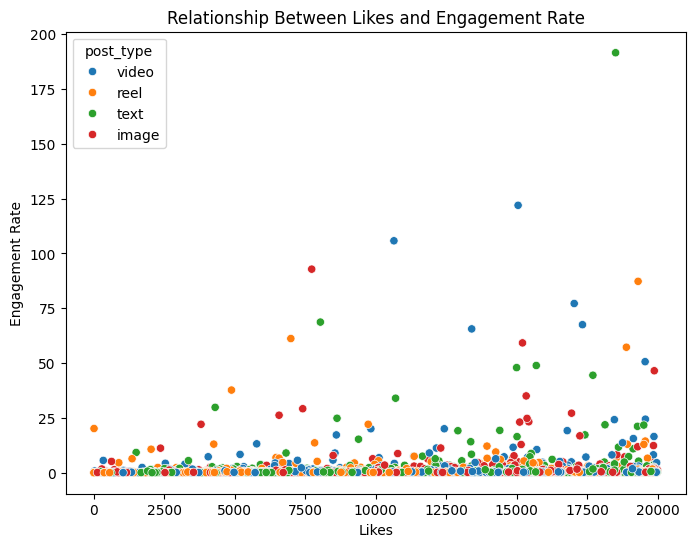

In [30]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='likes',
    y='engagement_rate',
    hue='post_type'
)

plt.xlabel('Likes')
plt.ylabel('Engagement Rate')
plt.title('Relationship Between Likes and Engagement Rate')

plt.show()

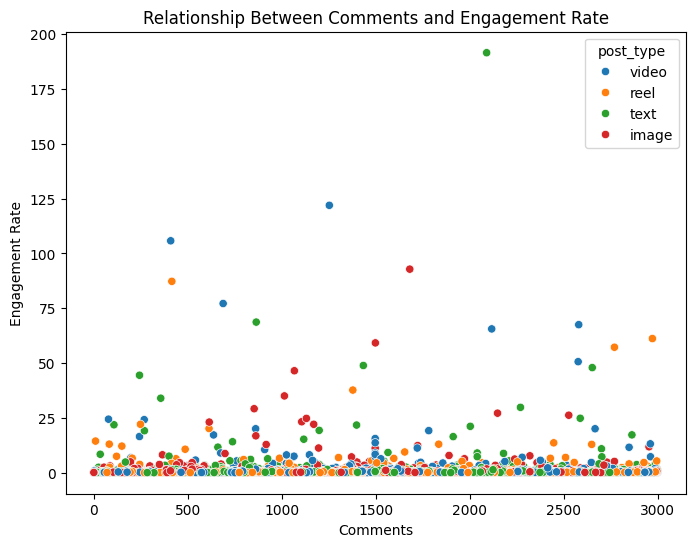

In [31]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='comments',
    y='engagement_rate',
    hue='post_type'
)

plt.xlabel('Comments')
plt.ylabel('Engagement Rate')
plt.title('Relationship Between Comments and Engagement Rate')

plt.show()

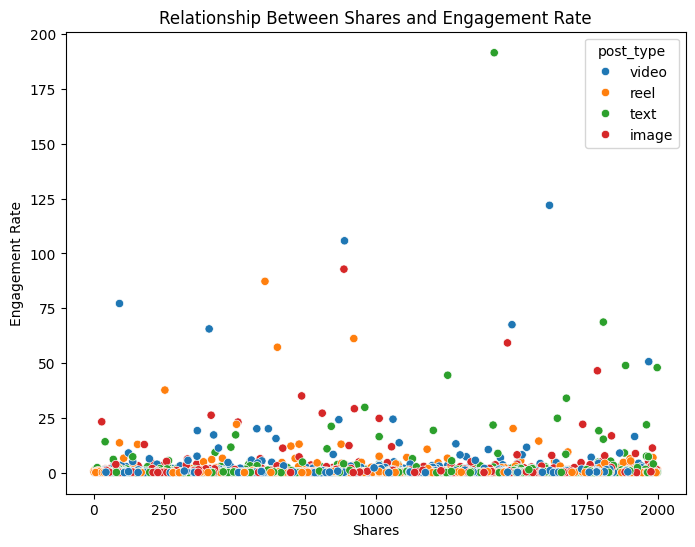

In [32]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='shares',
    y='engagement_rate',
    hue='post_type'
)

plt.xlabel('Shares')
plt.ylabel('Engagement Rate')
plt.title('Relationship Between Shares and Engagement Rate')

plt.show()

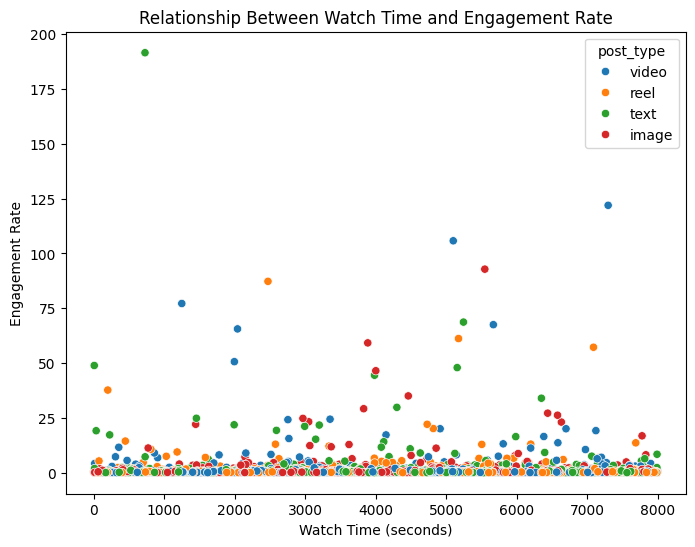

In [33]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='watch_time_sec',
    y='engagement_rate',
    hue='post_type'
)

plt.xlabel('Watch Time (seconds)')
plt.ylabel('Engagement Rate')
plt.title('Relationship Between Watch Time and Engagement Rate')

plt.show()

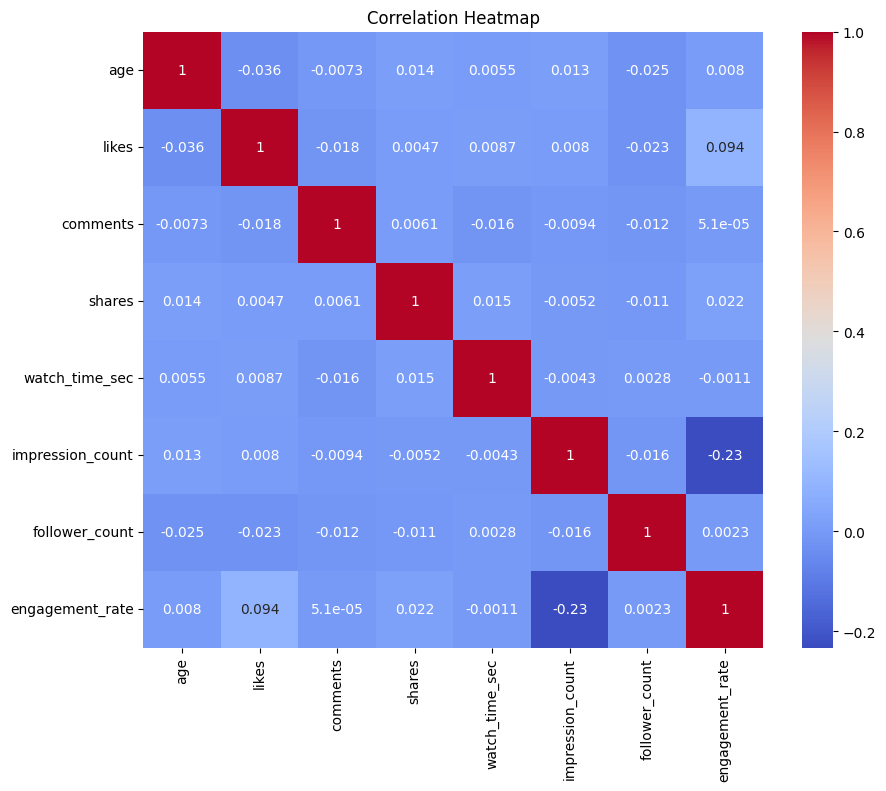

In [34]:
numeric_data = df[
    [
        'age',
        'likes',
        'comments',
        'shares',
        'watch_time_sec',
        'impression_count',
        'follower_count',
        'engagement_rate'
    ]
]

correlation = numeric_data.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')

plt.show()

In [35]:
device_engagement = df.groupby(
    'device_type'
)['engagement_rate'].mean()

device_engagement

,engagement_rate
device_type,
desktop,0.962006
mobile,1.123999
tablet,0.804560


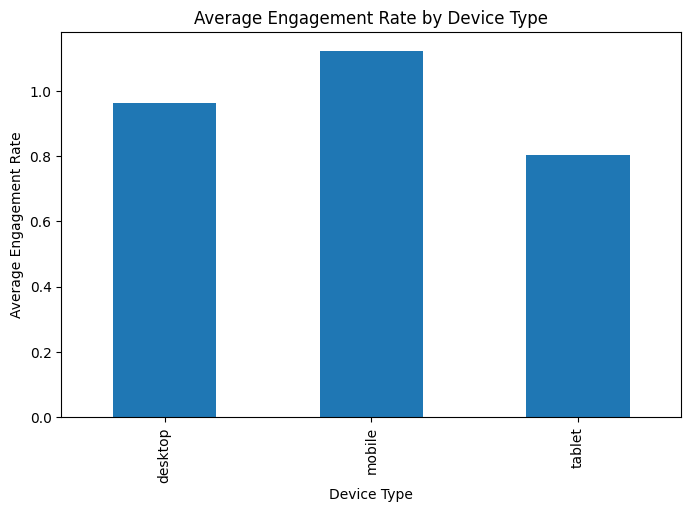

In [36]:
device_engagement.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Device Type')
plt.ylabel('Average Engagement Rate')
plt.title('Average Engagement Rate by Device Type')

plt.show()

In [37]:
verified_engagement = df.groupby(
    'is_verified'
)['engagement_rate'].mean()

verified_engagement

,engagement_rate
is_verified,
False,0.954744
True,1.054250


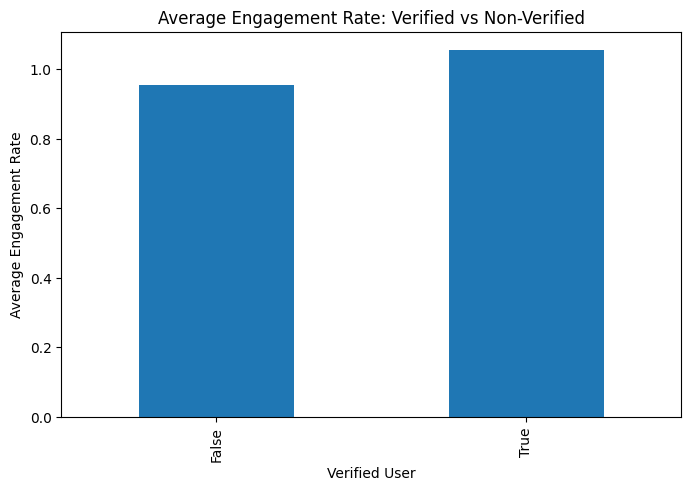

In [38]:
verified_engagement.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Verified User')
plt.ylabel('Average Engagement Rate')
plt.title('Average Engagement Rate: Verified vs Non-Verified')

plt.show()

In [39]:
country_engagement = df.groupby(
    'country'
)['engagement_rate'].mean().sort_values(
    ascending=False
)

country_engagement

,engagement_rate
country,
Brazil,1.540704
Australia,1.324339
France,1.146402
UAE,1.112352
Canada,0.916659
UK,0.850966
Japan,0.769623
Germany,0.759000
India,0.655005


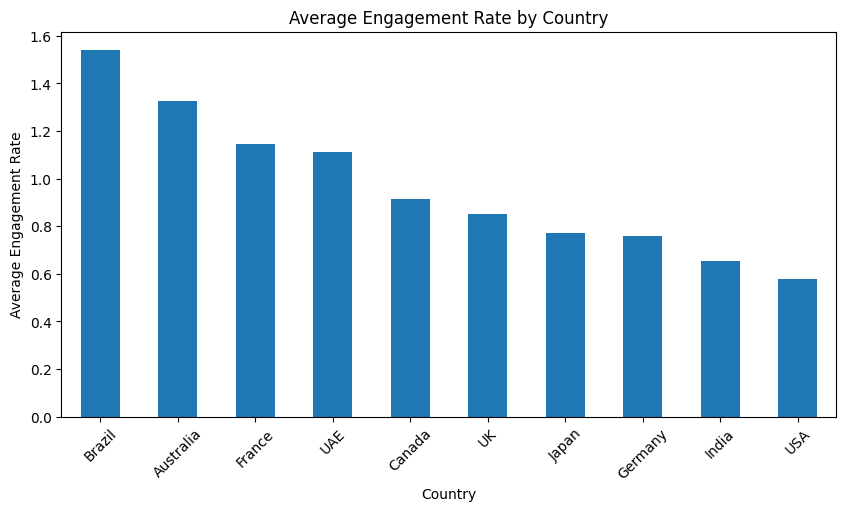

In [40]:
country_engagement.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.xlabel('Country')
plt.ylabel('Average Engagement Rate')
plt.title('Average Engagement Rate by Country')

plt.xticks(rotation=45)

plt.show()

In [41]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 18, 25, 35, 45, 55, 65, 100],
    labels=[
        'Under 18',
        '18-25',
        '26-35',
        '36-45',
        '46-55',
        '56-65',
        '65+'
    ]
)

In [42]:
age_engagement = df.groupby(
    'age_group',
    observed=True
)['engagement_rate'].mean()

age_engagement

,engagement_rate
age_group,
Under 18,0.867038
18-25,1.059536
26-35,0.865316
36-45,0.860741
46-55,1.414058
56-65,0.709213


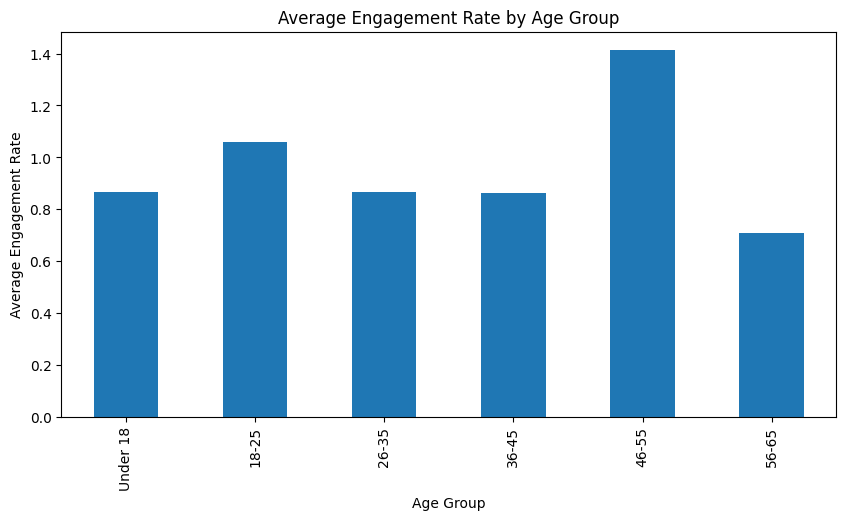

In [43]:
age_engagement.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.xlabel('Age Group')
plt.ylabel('Average Engagement Rate')
plt.title('Average Engagement Rate by Age Group')

plt.show()

In [44]:
hashtags = df['hashtags'].str.split()

all_hashtags = hashtags.explode()

hashtag_counts = all_hashtags.value_counts()

hashtag_counts.head(10)

,count
hashtags,
#tech,1045
#foodie,1037
#lifestyle,1024
#reels,1007
#fashion,1006
#fun,1005
#music,984
#fitness,978
#love,972


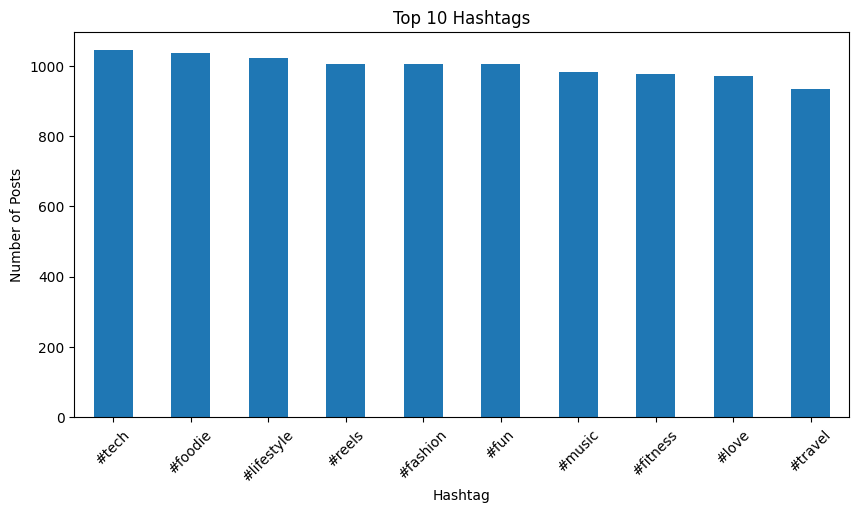

In [45]:
hashtag_counts.head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.xlabel('Hashtag')
plt.ylabel('Number of Posts')
plt.title('Top 10 Hashtags')

plt.xticks(rotation=45)

plt.show()

In [46]:
print("Dataset Shape:", df.shape)

print("\nAverage Engagement Rate:")
print(df['engagement_rate'].mean())

print("\nAverage Engagement by Post Type:")
print(df.groupby('post_type')['engagement_rate'].mean())

print("\nAverage Engagement by Sentiment:")
print(df.groupby('sentiment')['engagement_rate'].mean())

print("\nAverage Engagement by Device:")
print(df.groupby('device_type')['engagement_rate'].mean())

Dataset Shape: (5000, 20)

Average Engagement Rate:
0.9643560291584001

Average Engagement by Post Type:
post_type
image    0.895646
reel     0.783047
text     1.064549
video    1.122365
Name: engagement_rate, dtype: float64

Average Engagement by Sentiment:
sentiment
negative    1.038486
neutral     0.991170
positive    0.919744
Name: engagement_rate, dtype: float64

Average Engagement by Device:
device_type
desktop    0.962006
mobile     1.123999
tablet     0.804560
Name: engagement_rate, dtype: float64


In [47]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [49]:
df = pd.read_csv("social_media_engagement_5000.csv")


In [50]:
df.head()
df.columns
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


In [51]:
df.isnull().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


In [52]:
df = pd.read_csv("social_media_engagement_5000.csv")
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
